In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
viswaprakash1990_garbage_detection_path = kagglehub.dataset_download('viswaprakash1990/garbage-detection')

print('Data source import complete.')


Using Colab cache for faster access to the 'garbage-detection' dataset.
Data source import complete.


In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Streaming output truncated to the last 5000 lines.
/kaggle/input/garbage-detection/GARBAGE CLASSIFICATION/train/images/glass2030_jpg.rf.76e193b463aca4c35725d4525a175d0b.jpg
/kaggle/input/garbage-detection/GARBAGE CLASSIFICATION/train/images/cardboard1310_jpg.rf.eb3be44534b0c839b108d92068e0e78c.jpg
/kaggle/input/garbage-detection/GARBAGE CLASSIFICATION/train/images/glass506_jpg.rf.11e14d50feb2bad1bda63c9e631d315c.jpg
/kaggle/input/garbage-detection/GARBAGE CLASSIFICATION/train/images/glass1854_jpg.rf.92bfc70636094da61036a97861a21531.jpg
/kaggle/input/garbage-detection/GARBAGE CLASSIFICATION/train/images/cardboard298_jpg.rf.f35ea7704d9e8366cc4aa7dd9e28000a.jpg
/kaggle/input/garbage-detection/GARBAGE CLASSIFICATION/train/images/cardboard341_jpg.rf.5192eacad41fa06878b6560dc8b471c8.jpg
/kaggle/input/garbage-detection/GARBAGE CLASSIFICATION/train/images/metal477_jpg.rf.6e2a47192fd40efdca77e9b892275a00.jpg
/kaggle/input/garbage-detection/GARBAGE CLASSIFICATION/train/images/glass1041_jpg.rf.f4

In [ ]:
# --- Download dataset (Colab) ---
!pip install -q kagglehub
import kagglehub, os

path = kagglehub.dataset_download("viswaprakash1990/garbage-detection")
print("Downloaded to:", path)

# --- Find the YAML ---
yamls = [os.path.join(r, f) for r, d, fs in os.walk(path, followlinks=True)
         for f in fs if f.lower().endswith(('.yaml', '.yml'))]
print("YAML files:", yamls)

# --- Show folder structure (3 levels) ---
for r, d, fs in os.walk(path):
    depth = r.count(os.sep) - path.count(os.sep)
    if depth <= 3:
        print('  ' * depth + os.path.basename(r) + f'/  ({len(fs)} files)')

# --- Print YAML content (class names + paths) ---
if yamls:
    print("\n----- YAML content -----")
    print(open(yamls[0]).read())

Using Colab cache for faster access to the 'garbage-detection' dataset.
Downloaded to: /kaggle/input/garbage-detection
YAML files: ['/kaggle/input/garbage-detection/GARBAGE CLASSIFICATION/data.yaml']
garbage-detection/  (0 files)
  GARBAGE CLASSIFICATION/  (1 files)
    valid/  (0 files)
      labels/  (2098 files)
      images/  (2098 files)
    test/  (0 files)
      labels/  (1042 files)
      images/  (1042 files)
    train/  (0 files)
      labels/  (7324 files)
      images/  (7324 files)

----- YAML content -----
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 6
names: ['BIODEGRADABLE', 'CARDBOARD', 'GLASS', 'METAL', 'PAPER', 'PLASTIC']

roboflow:
  workspace: material-identification
  project: garbage-classification-3
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/material-identification/garbage-classification-3/dataset/2


In [ ]:
"""
APPLY THE BALANCED RE-SPLIT (resplit_assignment.csv)  ->  COCO-format dataset for RF-DETR AND the YOLOv8n script
------------------------------------------------------------------------------------------------------------------
Input : the ORIGINAL dataset "GARBAGE CLASSIFICATION" (YOLO format: train/ valid/ test/ -> images/ + labels/)
        + resplit_assignment.csv  (from Dataset_splitting.ipynb; one row per OLD valid/test image:
                                   image, group, orig_split, new_split)
        train/ is NOT in the file: it is unchanged and taken as-is from the original dataset.
Output: OUT_DIR/train/  OUT_DIR/valid/  OUT_DIR/test/
        each with the images + _annotations.coco.json   (layout RF-DETR detects as COCO)

Checks performed:
  1. every source image + label exists
  2. no image is assigned twice, and no source group (Roboflow id before '.rf.') is shared between splits
  3. per-split image / per-class image and box counts compared with the Dataset_splitting.ipynb results

Google Colab version (same logic as the Kaggle script used for YOLOv8n):
  - original dataset downloaded with kagglehub
  - resplit_assignment.csv read from Google Drive (saved there by Dataset_splitting.ipynb)
"""

import json, os, shutil
from collections import defaultdict
from pathlib import Path

import kagglehub
import pandas as pd
from PIL import Image
from google.colab import drive

drive.mount("/content/drive")

# ======================= EDIT THESE =======================
SRC_DIR      = None    # None = download with kagglehub ('viswaprakash1990/garbage-detection')
ASSIGNMENT   = Path("/content/drive/MyDrive/garbage_outputs/resplit_assignment.csv")   # None = search Drive for it
OUT_DIR      = Path("/content/garbage_balanced_coco")
COPY_IMAGES  = False   # False = symlink (fast, no disk use). True = real copies (needed only if you copy OUT_DIR to Drive)
CLASS_NAMES  = None    # None = read from SRC_DIR/data.yaml ; or give the list in YOLO id order
SPLITS       = ["train", "valid", "test"]
ANN_NAME     = "_annotations.coco.json"
# ==========================================================

# Expected results from Dataset_splitting.ipynb (after removing the 17 zero-area boxes)
EXPECTED_IMAGES = {"train": 7324, "valid": 1571, "test": 1569}
EXPECTED = {  # class: {split: (images containing the class, boxes)}
    "BIODEGRADABLE": {"train": (1603, 31714), "valid": (342, 6991), "test": (342, 6690)},
    "CARDBOARD":     {"train": (1053, 3385),  "valid": (224, 673),  "test": (225, 638)},
    "GLASS":         {"train": (1879, 5429),  "valid": (408, 1335), "test": (397, 1045)},
    "METAL":         {"train": (1328, 3948),  "valid": (285, 1078), "test": (285, 815)},
    "PAPER":         {"train": (1238, 2979),  "valid": (265, 656),  "test": (265, 752)},
    "PLASTIC":       {"train": (1019, 4146),  "valid": (222, 828),  "test": (223, 971)},
}


# ---------------------------------------------------------------- dataset location
if SRC_DIR is None:
    dl = Path(kagglehub.dataset_download("viswaprakash1990/garbage-detection"))
    SRC_DIR = sorted(dl.rglob("data.yaml"))[0].parent
print("Dataset:", SRC_DIR)

# ---------------------------------------------------------------- class names
if CLASS_NAMES is None:
    import yaml
    yml = next((p for p in [SRC_DIR / "data.yaml", SRC_DIR / "data.yml"] if p.exists()), None)
    assert yml, f"No data.yaml in {SRC_DIR}: set CLASS_NAMES manually (YOLO id order)"
    names = yaml.safe_load(yml.read_text())["names"]
    CLASS_NAMES = [names[i] for i in sorted(names)] if isinstance(names, dict) else list(names)
print("Classes (YOLO id -> name):", dict(enumerate(CLASS_NAMES)))

# ---------------------------------------------------------------- assignment file
if ASSIGNMENT is None or not Path(ASSIGNMENT).exists():
    found = sorted(Path("/content/drive/MyDrive").rglob("resplit_assignment*.csv"))
    assert found, "resplit_assignment.csv not found in Google Drive: upload it or set ASSIGNMENT"
    ASSIGNMENT = found[0]
print("Assignment file:", ASSIGNMENT)

a = pd.read_csv(ASSIGNMENT)
assert {"image", "orig_split", "new_split"} <= set(a.columns), f"Unexpected columns: {list(a.columns)}"
assert set(a["orig_split"]) <= {"valid", "test"}, f"Unexpected orig_split values: {set(a['orig_split'])}"
assert set(a["new_split"]) <= {"valid", "test"}, f"Unexpected new_split values: {set(a['new_split'])}"
print("Assignment rows:", len(a), "(expected 3140)")

# train is unchanged -> add it from the original dataset
train_imgs = sorted(p.name for p in (SRC_DIR / "train" / "images").iterdir() if p.is_file())
train = pd.DataFrame({"image": train_imgs, "orig_split": "train", "new_split": "train"})
man = pd.concat([train, a[["image", "orig_split", "new_split"]]], ignore_index=True)

man["src_img"] = [SRC_DIR / s / "images" / i for s, i in zip(man["orig_split"], man["image"])]
man["src_lbl"] = [SRC_DIR / s / "labels" / (Path(i).stem + ".txt") for s, i in zip(man["orig_split"], man["image"])]
man["new_name"] = man["image"]
man["group"] = man["image"].map(lambda n: Path(n).stem.split(".rf.")[0])
print("Images per new split:", man["new_split"].value_counts().reindex(SPLITS).to_dict())

# ---------------------------------------------------------------- check 1: files exist
missing_img = [str(p) for p in man["src_img"] if not p.exists()]
missing_lbl = [str(p) for p in man["src_lbl"] if not p.exists()]
print(f"Missing images: {len(missing_img)} | missing labels: {len(missing_lbl)}")
if missing_img:
    print("  e.g.", missing_img[:3])
    raise SystemExit("Stop: some images are missing. Check SRC_DIR (it must contain train/ valid/ test/).")
if missing_lbl:
    print("  e.g.", missing_lbl[:3], "\n  (images without a label file are treated as having no objects)")

# ---------------------------------------------------------------- check 2: duplicates + leakage
dups = man["image"].duplicated().sum()
print("Images assigned more than once:", dups)
if dups:
    raise SystemExit("Stop: some images appear more than once in the split.")
leak = {f"{x}-{y}": len(set(man[man.new_split == x].group) & set(man[man.new_split == y].group))
        for x, y in [("train", "valid"), ("train", "test"), ("valid", "test")]}
print("Shared source groups:", leak)
if any(leak.values()):
    raise SystemExit("Stop: the same source image group appears in more than one split (leakage).")

# ---------------------------------------------------------------- build COCO dataset
def yolo_line_to_xywh(parts, W, H):
    """Box line: cls cx cy w h  |  polygon line: cls x1 y1 x2 y2 ...  (all normalised) -> COCO xywh in pixels"""
    vals = [float(v) for v in parts[1:]]
    if len(vals) == 4:
        cx, cy, w, h = vals
        x, y = (cx - w / 2) * W, (cy - h / 2) * H
        return [x, y, w * W, h * H]
    xs, ys = vals[0::2], vals[1::2]
    x1, y1, x2, y2 = min(xs) * W, min(ys) * H, max(xs) * W, max(ys) * H
    return [x1, y1, x2 - x1, y2 - y1]

recount = []
for split in SPLITS:
    sdir = OUT_DIR / split
    sdir.mkdir(parents=True, exist_ok=True)
    rows = man[man["new_split"] == split]
    images, anns = [], []
    img_with_cls = defaultdict(set)
    box_count = defaultdict(int)
    skipped = 0

    for img_id, r in enumerate(rows.itertuples(index=False)):
        dst = sdir / r.new_name
        if not dst.exists():
            shutil.copy2(r.src_img, dst) if COPY_IMAGES else os.symlink(r.src_img, dst)
        with Image.open(r.src_img) as im:
            W, H = im.size
        images.append({"id": img_id, "file_name": r.new_name, "width": W, "height": H})

        if r.src_lbl.exists():
            for line in r.src_lbl.read_text().splitlines():
                parts = line.split()
                if len(parts) < 5:
                    continue
                c = int(float(parts[0]))
                x, y, w, h = yolo_line_to_xywh(parts, W, H)
                x, y = max(0.0, x), max(0.0, y)
                w, h = min(w, W - x), min(h, H - y)
                if w <= 0 or h <= 0:
                    skipped += 1
                    continue
                anns.append({"id": len(anns), "image_id": img_id, "category_id": c,
                             "bbox": [round(x, 2), round(y, 2), round(w, 2), round(h, 2)],
                             "area": round(w * h, 2), "iscrowd": 0})
                img_with_cls[c].add(img_id)
                box_count[c] += 1

    coco = {"images": images, "annotations": anns,
            "categories": [{"id": i, "name": n, "supercategory": "garbage"} for i, n in enumerate(CLASS_NAMES)]}
    (sdir / ANN_NAME).write_text(json.dumps(coco))
    print(f"{split:5s}: {len(images)} images, {len(anns)} boxes written"
          + (f" ({skipped} degenerate boxes skipped)" if skipped else ""))

    row = {"split": split, "images": len(images)}
    for i, n in enumerate(CLASS_NAMES):
        row[f"{n} image_count"] = len(img_with_cls[i])
        row[f"{n} boxes"] = box_count[i]
    recount.append(row)

# ---------------------------------------------------------------- check 3: compare with Dataset_splitting.ipynb
rec = pd.DataFrame(recount).set_index("split")
rec.to_csv(OUT_DIR / "split_summary_recomputed.csv")
man[["image", "group", "orig_split", "new_split"]].to_csv(OUT_DIR / "final_split.csv", index=False)
print("\nRecomputed summary:\n", rec.to_string())

ref = {}
for s in SPLITS:
    ref[s] = {"images": EXPECTED_IMAGES[s]}
    for n, d in EXPECTED.items():
        ref[s][f"{n} image_count"], ref[s][f"{n} boxes"] = d[s]
ref = pd.DataFrame(ref).T
norm = lambda c: c.strip().upper()                       # class names may differ in case
rec_n, ref_n = rec.rename(columns=norm), ref.rename(columns=norm)
missing = sorted(set(ref_n.columns) - set(rec_n.columns))
if missing:
    raise SystemExit(f"Stop: these expected columns have no matching class in data.yaml: {missing}")
cols = list(ref_n.columns)
diff = (rec_n.loc[SPLITS, cols] - ref_n.loc[SPLITS, cols])
if (diff == 0).all().all():
    print("\nOK: recomputed counts match Dataset_splitting.ipynb exactly.")
else:
    print("\nWARNING: counts differ from Dataset_splitting.ipynb (recomputed - expected):")
    print(diff.loc[:, (diff != 0).any()].to_string())

print("\nDataset ready:", OUT_DIR)

Mounted at /content/drive
Using Colab cache for faster access to the 'garbage-detection' dataset.
Dataset: /kaggle/input/garbage-detection/GARBAGE CLASSIFICATION
Classes (YOLO id -> name): {0: 'BIODEGRADABLE', 1: 'CARDBOARD', 2: 'GLASS', 3: 'METAL', 4: 'PAPER', 5: 'PLASTIC'}
Assignment file: /content/drive/MyDrive/garbage_outputs/resplit_assignment.csv
Assignment rows: 3140 (expected 3140)
Images per new split: {'train': 7324, 'valid': 1571, 'test': 1569}
Missing images: 0 | missing labels: 0
Images assigned more than once: 0
Shared source groups: {'train-valid': 0, 'train-test': 0, 'valid-test': 0}
train: 7324 images, 51601 boxes written (10 degenerate boxes skipped)
valid: 1571 images, 11561 boxes written (2 degenerate boxes skipped)
test : 1569 images, 10911 boxes written (5 degenerate boxes skipped)

Recomputed summary:
        images  BIODEGRADABLE image_count  BIODEGRADABLE boxes  CARDBOARD image_count  CARDBOARD boxes  GLASS image_count  GLASS boxes  METAL image_count  METAL box

In [ ]:
!pip install -q ultralytics
import os, yaml, shutil
import pandas as pd
from ultralytics import YOLO

yaml_path = [os.path.join(r, 'data.yaml') for r, d, f in os.walk('/kaggle/input', followlinks=True)
             if 'data.yaml' in f][0]
DATA_DIR = os.path.dirname(yaml_path)
cfg = yaml.safe_load(open(yaml_path))
names = cfg['names'] if isinstance(cfg['names'], list) else list(cfg['names'].values())
print(DATA_DIR, names)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 6.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
/kaggle/input/garbage-detection/GARBAGE CLASSIFICATION ['BIODEGRADABLE', 'CARDBOARD', 'GLASS', 'METAL', 'PAPER', 'PLASTIC']


In [ ]:
DATA_YAML = '/kaggle/working/garbage_resplit/data.yaml'

In [ ]:
import os, glob, shutil, yaml, torch
import pandas as pd
from pathlib import Path
import kagglehub
from google.colab import drive

drive.mount('/content/drive')

# 1) Original dataset + re-split assignment (saved by Dataset_splitting.ipynb)
SRC = sorted(Path(kagglehub.dataset_download('viswaprakash1990/garbage-detection')).rglob('data.yaml'))[0].parent
ASSIGN = Path('/content/drive/MyDrive/garbage_outputs/resplit_assignment.csv')
NEW_ROOT = Path('/content/garbage_resplit')
S = ['train', 'valid', 'test']

names = yaml.safe_load(open(SRC / 'data.yaml'))['names']
NAMES = [names[i] for i in sorted(names)] if isinstance(names, dict) else list(names)
a = pd.read_csv(ASSIGN)
print('Classes:', NAMES, '| assignment rows:', len(a), '(expected 3140)')

# 2) train unchanged + valid/test from the assignment file
train = pd.DataFrame({'image': sorted(p.name for p in (SRC / 'train' / 'images').iterdir())})
train['orig_split'] = 'train'; train['new_split'] = 'train'
allr = pd.concat([train, a[['image', 'orig_split', 'new_split']]], ignore_index=True)

def clean(lines):  # remove zero-area boxes (same rule as Dataset_splitting.ipynb)
    return [l for l in lines if len(l.split()) == 5 and float(l.split()[3]) > 0 and float(l.split()[4]) > 0]

if NEW_ROOT.exists(): shutil.rmtree(NEW_ROOT)
for s in S:
    (NEW_ROOT / s / 'images').mkdir(parents=True); (NEW_ROOT / s / 'labels').mkdir(parents=True)

removed = 0
for r in allr.itertuples():
    stem = Path(r.image).stem
    (NEW_ROOT / r.new_split / 'images' / r.image).symlink_to(SRC / r.orig_split / 'images' / r.image)
    lp = SRC / r.orig_split / 'labels' / (stem + '.txt')
    raw = lp.read_text().splitlines() if lp.exists() else []
    keep = clean(raw); removed += sum(1 for l in raw if l.strip()) - len(keep)
    (NEW_ROOT / r.new_split / 'labels' / (stem + '.txt')).write_text('\n'.join(keep) + ('\n' if keep else ''))

# 3) Verify
counts = [len(list((NEW_ROOT / s / 'images').iterdir())) for s in S]
print('Zero-area lines removed:', removed, '(expected 17)')
print('Images', dict(zip(S, counts)), '| match 7324/1571/1569:', counts == [7324, 1571, 1569])

DATA = str(NEW_ROOT)   # used by YoloDet

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using Colab cache for faster access to the 'garbage-detection' dataset.
Classes: ['BIODEGRADABLE', 'CARDBOARD', 'GLASS', 'METAL', 'PAPER', 'PLASTIC'] | assignment rows: 3140 (expected 3140)
Zero-area lines removed: 17 (expected 17)
Images {'train': 7324, 'valid': 1571, 'test': 1569} | match 7324/1571/1569: True


In [ ]:
# ============================================================================================
# CELL 2 — SSDLite (MobileNetV3-Large) training on the re-split dataset   (Google Colab, T4 GPU)
# Needs CELL 1 first (it builds /content/garbage_resplit and defines DATA + NAMES).
# "YoloDet" is only the DATA READER (labels are stored in YOLO .txt format) — the MODEL is SSDLite.
# ============================================================================================
!pip -q install pycocotools

import os, glob, random, time
import numpy as np, pandas as pd, torch, torch.nn as nn
from functools import partial
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
from torchvision.models.detection import ssdlite320_mobilenet_v3_large, SSDLite320_MobileNet_V3_Large_Weights
from torchvision.models.detection.ssdlite import SSDLiteClassificationHead
from torchvision.models.detection import _utils as det_utils
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# ======================= EDIT THESE =======================
SEED, SIZE, CAP = 0, 320, 100     # CAP = max detections per image (same cap across models)
EPOCHS    = 150
BATCH     = 16
LR        = 0.01
PATIENCE  = 10                    # stop after N epochs without valid mAP@50-95 improvement
WORK_DIR  = "/content/drive/MyDrive/garbage_outputs/ssdlite_resplit"   # on Drive -> survives Colab resets
# ==========================================================

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
os.makedirs(WORK_DIR, exist_ok=True)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", dev, "| classes:", NAMES)


# ---------------------------------------------------------------- dataset (YOLO .txt labels -> torchvision targets)
class YoloDet(Dataset):
    """YOLO labels -> torchvision targets. Labels shifted +1 (0 = background in torchvision)."""
    def __init__(self, split, train=False):
        self.imgs = sorted(glob.glob(f"{DATA}/{split}/images/*"))
        self.split, self.train = split, train
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i):
        p = self.imgs[i]
        img = Image.open(p).convert("RGB"); w, h = img.size
        lbl = f"{DATA}/{self.split}/labels/{os.path.splitext(os.path.basename(p))[0]}.txt"
        rows = [l.split() for l in open(lbl).read().strip().splitlines() if l.strip()]
        b = torch.tensor([[(float(x)-float(bw)/2)*SIZE, (float(y)-float(bh)/2)*SIZE,
                           (float(x)+float(bw)/2)*SIZE, (float(y)+float(bh)/2)*SIZE]
                          for _, x, y, bw, bh in rows], dtype=torch.float32).reshape(-1, 4).clamp(0, SIZE)
        c = torch.tensor([int(r[0]) + 1 for r in rows], dtype=torch.int64)
        if self.train:                                   # drop degenerate boxes (training only)
            keep = ((b[:, 2] - b[:, 0]) > 1) & ((b[:, 3] - b[:, 1]) > 1)
            b, c = b[keep], c[keep]
        x = TF.to_tensor(img.resize((SIZE, SIZE)))
        if self.train and random.random() < 0.5:         # horizontal flip
            x = x.flip(-1); b[:, [0, 2]] = SIZE - b[:, [2, 0]]
        return x, {"boxes": b, "labels": c, "orig_size": (w, h), "path": p}

collate = lambda batch: tuple(zip(*batch))
g = torch.Generator().manual_seed(SEED)
train_ds, val_ds = YoloDet("train", True), YoloDet("valid")
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2, collate_fn=collate, generator=g)
val_dl   = DataLoader(val_ds, batch_size=32, num_workers=2, collate_fn=collate)
print("Images  train:", len(train_ds), "| valid:", len(val_ds))


# ---------------------------------------------------------------- model (COCO-pretrained, new class head)
def build_model():
    m = ssdlite320_mobilenet_v3_large(weights=SSDLite320_MobileNet_V3_Large_Weights.COCO_V1)
    in_ch = det_utils.retrieve_out_channels(m.backbone, (SIZE, SIZE))
    n_anchors = m.anchor_generator.num_anchors_per_location()
    m.head.classification_head = SSDLiteClassificationHead(
        in_ch, n_anchors, len(NAMES) + 1, partial(nn.BatchNorm2d, eps=0.001, momentum=0.03))
    m.detections_per_img = CAP                            # same detection cap across models
    return m

model = build_model().to(dev)
opt = torch.optim.SGD(model.parameters(), lr=LR, momentum=0.9, weight_decay=4e-5)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)


# ---------------------------------------------------------------- valid mAP (pycocotools, 320x320 coordinates)
def make_val_gt():
    images, anns = [], []
    for i in range(len(val_ds)):
        _, t = val_ds[i]
        images.append({"id": i, "width": SIZE, "height": SIZE})
        for (x1, y1, x2, y2), c in zip(t["boxes"].tolist(), t["labels"].tolist()):
            if x2 > x1 and y2 > y1:
                anns.append({"id": len(anns), "image_id": i, "category_id": c, "iscrowd": 0,
                             "bbox": [x1, y1, x2 - x1, y2 - y1], "area": (x2 - x1) * (y2 - y1)})
    gt = COCO(); gt.dataset = {"images": images, "annotations": anns,
                               "categories": [{"id": k + 1, "name": n} for k, n in enumerate(NAMES)]}
    gt.createIndex(); return gt

val_gt = make_val_gt()

@torch.no_grad()
def valid_map():
    model.eval(); dets, idx = [], 0
    for imgs, _ in val_dl:
        for o in model([x.to(dev) for x in imgs]):
            for (x1, y1, x2, y2), c, s in zip(o["boxes"].tolist(), o["labels"].tolist(), o["scores"].tolist()):
                dets.append({"image_id": idx, "category_id": c, "score": s, "bbox": [x1, y1, x2 - x1, y2 - y1]})
            idx += 1
    if not dets: return 0.0, 0.0
    E = COCOeval(val_gt, val_gt.loadRes(dets), "bbox")
    E.params.maxDets = [1, 10, CAP]
    E.evaluate(); E.accumulate()
    p = E.eval["precision"][:, :, :, 0, -1]
    return float(p[p > -1].mean()), float(p[0][p[0] > -1].mean())    # mAP@50-95, mAP@50


# ---------------------------------------------------------------- resume (if Colab was reset)
best_pt, last_pt = f"{WORK_DIR}/best.pt", f"{WORK_DIR}/last.pt"
start, best, bad, history = 0, -1.0, 0, []
if os.path.exists(last_pt):
    ck = torch.load(last_pt, map_location=dev, weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
    start, best, bad, history = ck["epoch"] + 1, ck["best"], ck["bad"], ck["history"]
    print(f"Resuming from epoch {start + 1} (best valid mAP@50-95 = {best:.4f})")


# ---------------------------------------------------------------- train
for ep in range(start, EPOCHS):
    model.train(); t0, tot = time.time(), 0.0
    for imgs, tgts in train_dl:
        imgs = [x.to(dev) for x in imgs]
        tgts = [{"boxes": t["boxes"].to(dev), "labels": t["labels"].to(dev)} for t in tgts]
        loss = sum(model(imgs, tgts).values())
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item()
    sched.step()

    m5095, m50 = valid_map()
    history.append({"epoch": ep + 1, "train_loss": tot / len(train_dl), "val_mAP50": m50, "val_mAP50-95": m5095})
    print(f"Epoch {ep + 1}/{EPOCHS}  loss {tot / len(train_dl):.4f}  val mAP@50 {m50:.4f}  "
          f"mAP@50-95 {m5095:.4f}  ({time.time() - t0:.0f}s)")

    if m5095 > best:
        best, bad = m5095, 0
        torch.save(model.state_dict(), best_pt)
    else:
        bad += 1
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                "epoch": ep, "best": best, "bad": bad, "history": history}, last_pt)
    pd.DataFrame(history).to_csv(f"{WORK_DIR}/history.csv", index=False)
    if bad >= PATIENCE:
        print(f"Early stopping: no improvement for {PATIENCE} epochs"); break

print(f"\nBest valid mAP@50-95: {best:.4f}  ->  {best_pt}")

Device: cuda | classes: ['BIODEGRADABLE', 'CARDBOARD', 'GLASS', 'METAL', 'PAPER', 'PLASTIC']
Images  train: 7324 | valid: 1571
Downloading: "https://download.pytorch.org/models/ssdlite320_mobilenet_v3_large_coco-a79551df.pth" to /root/.cache/torch/hub/checkpoints/ssdlite320_mobilenet_v3_large_coco-a79551df.pth


100%|██████████| 13.4M/13.4M [00:00<00:00, 112MB/s]


creating index...
index created!
Loading and preparing results...
DONE (t=0.43s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=14.16s).
Accumulating evaluation results...
DONE (t=1.72s).
Epoch 1/150  loss 4.7486  val mAP@50 0.2384  mAP@50-95 0.1354  (129s)
Loading and preparing results...
DONE (t=0.46s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=14.67s).
Accumulating evaluation results...
DONE (t=2.76s).
Epoch 2/150  loss 3.8519  val mAP@50 0.3092  mAP@50-95 0.1827  (123s)
Loading and preparing results...
DONE (t=0.48s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=15.54s).
Accumulating evaluation results...
DONE (t=1.53s).
Epoch 3/150  loss 3.5611  val mAP@50 0.3546  mAP@50-95 0.2171  (124s)
Loading and preparing results...
DONE (t=0.58s)
creating index...
index created!
Running per image evaluation...
Evalu

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 10.6 MB/s eta 0:00:00
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using Colab cache for faster access to the 'garbage-detection' dataset.
Dataset: /kaggle/input/garbage-detection/GARBAGE CLASSIFICATION
Classes (YOLO id -> name): {0: 'BIODEGRADABLE', 1: 'CARDBOARD', 2: 'GLASS', 3: 'METAL', 4: 'PAPER', 5: 'PLASTIC'}
Assignment file: /content/drive/MyDrive/garbage_outputs/resplit_assignment.csv
Assignment rows: 3140 (expected 3140)
Images per new split: {'train': 7324, 'valid': 1571, 'test': 1569}
Missing images: 0 | missing labels: 0
Images assigned more than once: 0
Shared source groups: {'train-valid': 0, 'train-test': 0, 'valid-test': 0}
train: 7324 images, 51601 boxes written (10 degenerate

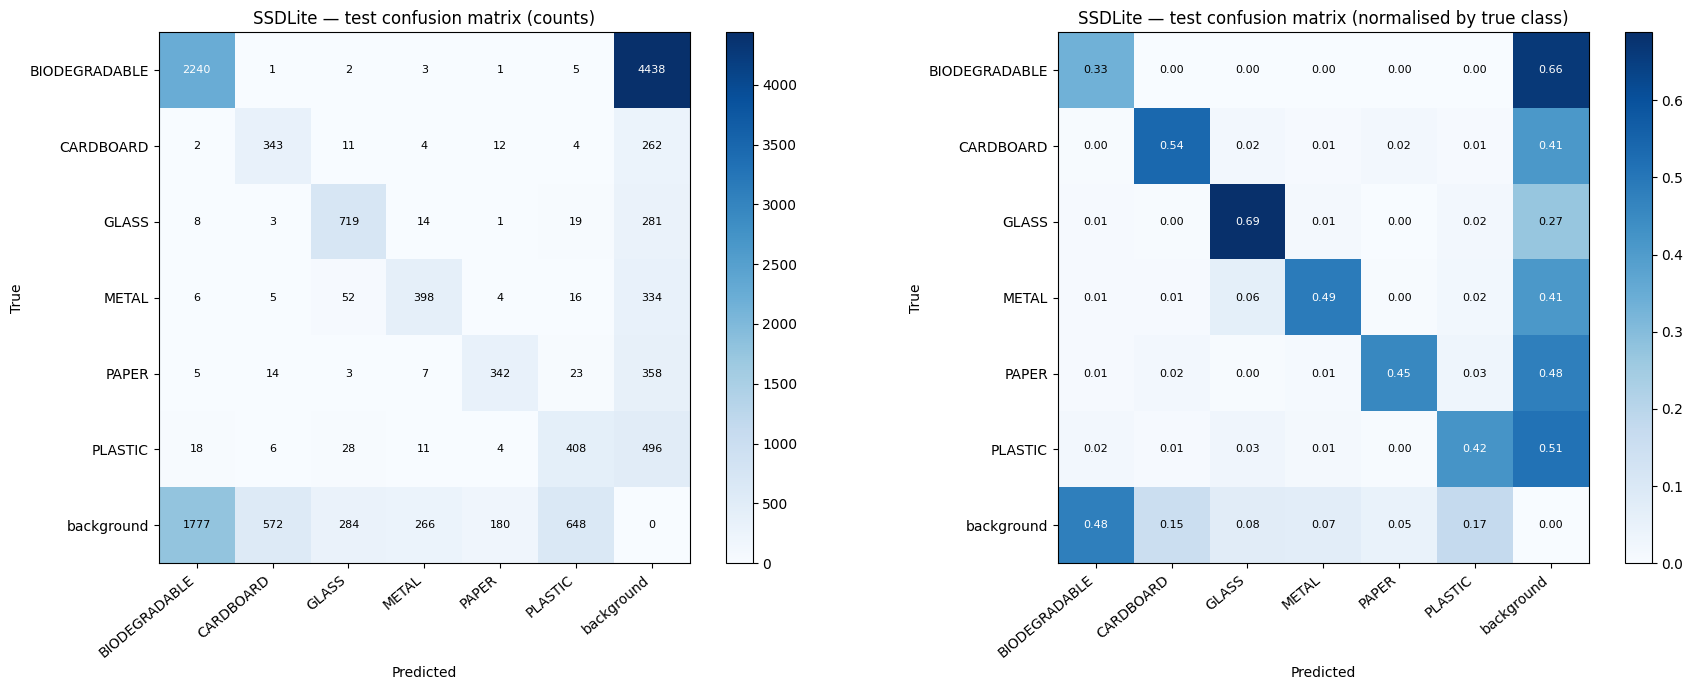


===== SSDLite — TEST  (P/R/F1 at conf >= 0.25, IoU >= 0.5) =====


,GT boxes,TP,FP,FN,Precision,Recall,F1,mAP@50,mAP@50-95
class,,,,,,,,,
BIODEGRADABLE,6690,2240,1816,4450,0.5523,0.3348,0.4169,0.3403,0.1800
CARDBOARD,638,343,601,295,0.3633,0.5376,0.4336,0.4867,0.3240
GLASS,1045,719,380,326,0.6542,0.6880,0.6707,0.7110,0.4849
METAL,815,398,305,417,0.5661,0.4883,0.5244,0.5713,0.3499
PAPER,752,342,202,410,0.6287,0.4548,0.5278,0.5109,0.3485
PLASTIC,971,408,715,563,0.3633,0.4202,0.3897,0.3757,0.2127



===== TEST SUMMARY (same evaluator for all models) =====


,Precision,Recall,F1,mAP@50,mAP@50-95,macro F1
model,,,,,,
SSDLite,0.5254,0.4078,0.4592,0.4993,0.3167,0.4938


Saved to /content/drive/MyDrive/garbage_outputs/eval_test


In [ ]:
# ============================================================================
# CELL 3 — EVALUATION (one cell): builds the test annotations, then evaluates
# ============================================================================
!pip -q install pycocotools ultralytics

# ----------------------------- PART A: build /content/garbage_balanced_coco -----------------------------
"""
APPLY THE BALANCED RE-SPLIT (resplit_assignment.csv)  ->  COCO-format dataset for RF-DETR AND the YOLOv8n script
------------------------------------------------------------------------------------------------------------------
Input : the ORIGINAL dataset "GARBAGE CLASSIFICATION" (YOLO format: train/ valid/ test/ -> images/ + labels/)
        + resplit_assignment.csv  (from Dataset_splitting.ipynb; one row per OLD valid/test image:
                                   image, group, orig_split, new_split)
        train/ is NOT in the file: it is unchanged and taken as-is from the original dataset.
Output: OUT_DIR/train/  OUT_DIR/valid/  OUT_DIR/test/
        each with the images + _annotations.coco.json   (layout RF-DETR detects as COCO)

Checks performed:
  1. every source image + label exists
  2. no image is assigned twice, and no source group (Roboflow id before '.rf.') is shared between splits
  3. per-split image / per-class image and box counts compared with the Dataset_splitting.ipynb results

Google Colab version (same logic as the Kaggle script used for YOLOv8n):
  - original dataset downloaded with kagglehub
  - resplit_assignment.csv read from Google Drive (saved there by Dataset_splitting.ipynb)
"""

import json, os, shutil
from collections import defaultdict
from pathlib import Path

import kagglehub
import pandas as pd
from PIL import Image
from google.colab import drive

drive.mount("/content/drive")

# ======================= EDIT THESE =======================
SRC_DIR      = None    # None = download with kagglehub ('viswaprakash1990/garbage-detection')
ASSIGNMENT   = Path("/content/drive/MyDrive/garbage_outputs/resplit_assignment.csv")   # None = search Drive for it
OUT_DIR      = Path("/content/garbage_balanced_coco")
COPY_IMAGES  = False   # False = symlink (fast, no disk use). True = real copies (needed only if you copy OUT_DIR to Drive)
CLASS_NAMES  = None    # None = read from SRC_DIR/data.yaml ; or give the list in YOLO id order
SPLITS       = ["train", "valid", "test"]
ANN_NAME     = "_annotations.coco.json"
# ==========================================================

# Expected results from Dataset_splitting.ipynb (after removing the 17 zero-area boxes)
EXPECTED_IMAGES = {"train": 7324, "valid": 1571, "test": 1569}
EXPECTED = {  # class: {split: (images containing the class, boxes)}
    "BIODEGRADABLE": {"train": (1603, 31714), "valid": (342, 6991), "test": (342, 6690)},
    "CARDBOARD":     {"train": (1053, 3385),  "valid": (224, 673),  "test": (225, 638)},
    "GLASS":         {"train": (1879, 5429),  "valid": (408, 1335), "test": (397, 1045)},
    "METAL":         {"train": (1328, 3948),  "valid": (285, 1078), "test": (285, 815)},
    "PAPER":         {"train": (1238, 2979),  "valid": (265, 656),  "test": (265, 752)},
    "PLASTIC":       {"train": (1019, 4146),  "valid": (222, 828),  "test": (223, 971)},
}


# ---------------------------------------------------------------- dataset location
if SRC_DIR is None:
    dl = Path(kagglehub.dataset_download("viswaprakash1990/garbage-detection"))
    SRC_DIR = sorted(dl.rglob("data.yaml"))[0].parent
print("Dataset:", SRC_DIR)

# ---------------------------------------------------------------- class names
if CLASS_NAMES is None:
    import yaml
    yml = next((p for p in [SRC_DIR / "data.yaml", SRC_DIR / "data.yml"] if p.exists()), None)
    assert yml, f"No data.yaml in {SRC_DIR}: set CLASS_NAMES manually (YOLO id order)"
    names = yaml.safe_load(yml.read_text())["names"]
    CLASS_NAMES = [names[i] for i in sorted(names)] if isinstance(names, dict) else list(names)
print("Classes (YOLO id -> name):", dict(enumerate(CLASS_NAMES)))

# ---------------------------------------------------------------- assignment file
if ASSIGNMENT is None or not Path(ASSIGNMENT).exists():
    found = sorted(Path("/content/drive/MyDrive").rglob("resplit_assignment*.csv"))
    assert found, "resplit_assignment.csv not found in Google Drive: upload it or set ASSIGNMENT"
    ASSIGNMENT = found[0]
print("Assignment file:", ASSIGNMENT)

a = pd.read_csv(ASSIGNMENT)
assert {"image", "orig_split", "new_split"} <= set(a.columns), f"Unexpected columns: {list(a.columns)}"
assert set(a["orig_split"]) <= {"valid", "test"}, f"Unexpected orig_split values: {set(a['orig_split'])}"
assert set(a["new_split"]) <= {"valid", "test"}, f"Unexpected new_split values: {set(a['new_split'])}"
print("Assignment rows:", len(a), "(expected 3140)")

# train is unchanged -> add it from the original dataset
train_imgs = sorted(p.name for p in (SRC_DIR / "train" / "images").iterdir() if p.is_file())
train = pd.DataFrame({"image": train_imgs, "orig_split": "train", "new_split": "train"})
man = pd.concat([train, a[["image", "orig_split", "new_split"]]], ignore_index=True)

man["src_img"] = [SRC_DIR / s / "images" / i for s, i in zip(man["orig_split"], man["image"])]
man["src_lbl"] = [SRC_DIR / s / "labels" / (Path(i).stem + ".txt") for s, i in zip(man["orig_split"], man["image"])]
man["new_name"] = man["image"]
man["group"] = man["image"].map(lambda n: Path(n).stem.split(".rf.")[0])
print("Images per new split:", man["new_split"].value_counts().reindex(SPLITS).to_dict())

# ---------------------------------------------------------------- check 1: files exist
missing_img = [str(p) for p in man["src_img"] if not p.exists()]
missing_lbl = [str(p) for p in man["src_lbl"] if not p.exists()]
print(f"Missing images: {len(missing_img)} | missing labels: {len(missing_lbl)}")
if missing_img:
    print("  e.g.", missing_img[:3])
    raise SystemExit("Stop: some images are missing. Check SRC_DIR (it must contain train/ valid/ test/).")
if missing_lbl:
    print("  e.g.", missing_lbl[:3], "\n  (images without a label file are treated as having no objects)")

# ---------------------------------------------------------------- check 2: duplicates + leakage
dups = man["image"].duplicated().sum()
print("Images assigned more than once:", dups)
if dups:
    raise SystemExit("Stop: some images appear more than once in the split.")
leak = {f"{x}-{y}": len(set(man[man.new_split == x].group) & set(man[man.new_split == y].group))
        for x, y in [("train", "valid"), ("train", "test"), ("valid", "test")]}
print("Shared source groups:", leak)
if any(leak.values()):
    raise SystemExit("Stop: the same source image group appears in more than one split (leakage).")

# ---------------------------------------------------------------- build COCO dataset
def yolo_line_to_xywh(parts, W, H):
    """Box line: cls cx cy w h  |  polygon line: cls x1 y1 x2 y2 ...  (all normalised) -> COCO xywh in pixels"""
    vals = [float(v) for v in parts[1:]]
    if len(vals) == 4:
        cx, cy, w, h = vals
        x, y = (cx - w / 2) * W, (cy - h / 2) * H
        return [x, y, w * W, h * H]
    xs, ys = vals[0::2], vals[1::2]
    x1, y1, x2, y2 = min(xs) * W, min(ys) * H, max(xs) * W, max(ys) * H
    return [x1, y1, x2 - x1, y2 - y1]

recount = []
for split in SPLITS:
    sdir = OUT_DIR / split
    sdir.mkdir(parents=True, exist_ok=True)
    rows = man[man["new_split"] == split]
    images, anns = [], []
    img_with_cls = defaultdict(set)
    box_count = defaultdict(int)
    skipped = 0

    for img_id, r in enumerate(rows.itertuples(index=False)):
        dst = sdir / r.new_name
        if not dst.exists():
            shutil.copy2(r.src_img, dst) if COPY_IMAGES else os.symlink(r.src_img, dst)
        with Image.open(r.src_img) as im:
            W, H = im.size
        images.append({"id": img_id, "file_name": r.new_name, "width": W, "height": H})

        if r.src_lbl.exists():
            for line in r.src_lbl.read_text().splitlines():
                parts = line.split()
                if len(parts) < 5:
                    continue
                c = int(float(parts[0]))
                x, y, w, h = yolo_line_to_xywh(parts, W, H)
                x, y = max(0.0, x), max(0.0, y)
                w, h = min(w, W - x), min(h, H - y)
                if w <= 0 or h <= 0:
                    skipped += 1
                    continue
                anns.append({"id": len(anns), "image_id": img_id, "category_id": c,
                             "bbox": [round(x, 2), round(y, 2), round(w, 2), round(h, 2)],
                             "area": round(w * h, 2), "iscrowd": 0})
                img_with_cls[c].add(img_id)
                box_count[c] += 1

    coco = {"images": images, "annotations": anns,
            "categories": [{"id": i, "name": n, "supercategory": "garbage"} for i, n in enumerate(CLASS_NAMES)]}
    (sdir / ANN_NAME).write_text(json.dumps(coco))
    print(f"{split:5s}: {len(images)} images, {len(anns)} boxes written"
          + (f" ({skipped} degenerate boxes skipped)" if skipped else ""))

    row = {"split": split, "images": len(images)}
    for i, n in enumerate(CLASS_NAMES):
        row[f"{n} image_count"] = len(img_with_cls[i])
        row[f"{n} boxes"] = box_count[i]
    recount.append(row)

# ---------------------------------------------------------------- check 3: compare with Dataset_splitting.ipynb
rec = pd.DataFrame(recount).set_index("split")
rec.to_csv(OUT_DIR / "split_summary_recomputed.csv")
man[["image", "group", "orig_split", "new_split"]].to_csv(OUT_DIR / "final_split.csv", index=False)
print("\nRecomputed summary:\n", rec.to_string())

ref = {}
for s in SPLITS:
    ref[s] = {"images": EXPECTED_IMAGES[s]}
    for n, d in EXPECTED.items():
        ref[s][f"{n} image_count"], ref[s][f"{n} boxes"] = d[s]
ref = pd.DataFrame(ref).T
norm = lambda c: c.strip().upper()                       # class names may differ in case
rec_n, ref_n = rec.rename(columns=norm), ref.rename(columns=norm)
missing = sorted(set(ref_n.columns) - set(rec_n.columns))
if missing:
    raise SystemExit(f"Stop: these expected columns have no matching class in data.yaml: {missing}")
cols = list(ref_n.columns)
diff = (rec_n.loc[SPLITS, cols] - ref_n.loc[SPLITS, cols])
if (diff == 0).all().all():
    print("\nOK: recomputed counts match Dataset_splitting.ipynb exactly.")
else:
    print("\nWARNING: counts differ from Dataset_splitting.ipynb (recomputed - expected):")
    print(diff.loc[:, (diff != 0).any()].to_string())

print("\nDataset ready:", OUT_DIR)


# ----------------------------- PART B: evaluate on the test set -----------------------------
"""
TEST-SET EVALUATION  ->  identical metrics for YOLOv8n and RF-DETR
-------------------------------------------------------------------
Ground truth : OUT_DIR/test/_annotations.coco.json   (built by apply_resplit_to_coco.py)
Metrics      : mAP@50, mAP@50-95  (pycocotools, COCO standard)
               Precision, Recall, F1, confusion matrix  (IoU >= 0.5, at a fixed confidence CONF)
               overall + per class
Why one script for both models: each library computes P/R/F1 differently (e.g. Ultralytics picks the
confidence with the best F1). Running both models through the SAME code makes the numbers comparable.

Google Colab:  !pip install -q pycocotools ultralytics
Run apply_resplit_to_coco_colab.py first (it builds OUT_DIR).
"""

import json, os
if not os.path.ismount("/content/drive"):
    from google.colab import drive; drive.mount("/content/drive")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# ======================= EDIT THESE =======================
OUT_DIR   = Path("/content/garbage_balanced_coco")            # from apply_resplit_to_coco_colab.py
EVAL_DIR  = Path("/content/drive/MyDrive/garbage_outputs/eval_test")   # on Drive
MODELS = {
    # name : (type, weights path)   -> delete the line of a model you don't have yet
    "SSDLite": ("ssdlite", "/content/drive/MyDrive/garbage_outputs/ssdlite_resplit/best.pt"),
    # YOLOv8n: upload its best.pt to Drive, then uncomment:
    # "YOLOv8n": ("yolo", "/content/drive/MyDrive/garbage_outputs/yolov8n_best.pt"),
}
RFDETR_CLASS = "RFDETRBase"   # the class you trained with: RFDETRNano / RFDETRSmall / RFDETRBase / RFDETRMedium ...
YOLO_IMGSZ   = 640           # must equal the imgsz used in training
CONF         = 0.25           # confidence for P / R / F1 / confusion matrix (same for both models)
IOU_MATCH    = 0.5            # IoU for a correct detection (P / R / F1 / confusion matrix)
MIN_CONF_MAP = 0.001          # keep (almost) all detections for mAP, as COCO / Ultralytics do
MAX_DET      = 100            # same cap as the SSDLite training (CAP = 100) -> same cap for every model
# ==========================================================

ANN = OUT_DIR / "test" / "_annotations.coco.json"
gt = COCO(str(ANN))
CATS = sorted(gt.getCatIds())
NAMES = [gt.cats[c]["name"] for c in CATS]
K = len(CATS)
print("Test images:", len(gt.imgs), "| GT boxes:", len(gt.anns), "| classes:", dict(zip(CATS, NAMES)))


# ---------------------------------------------------------------- predictors (return xyxy, class, score)
def make_predictor(kind, weights):
    if kind == "yolo":
        from ultralytics import YOLO
        m = YOLO(weights)
        def pred(path):
            r = m.predict(str(path), imgsz=YOLO_IMGSZ, conf=MIN_CONF_MAP, iou=0.7,
                          max_det=MAX_DET, verbose=False)[0].boxes
            return r.xyxy.cpu().numpy(), r.cls.cpu().numpy().astype(int), r.conf.cpu().numpy()
        return pred
    if kind == "rfdetr":
        import rfdetr
        m = getattr(rfdetr, RFDETR_CLASS)(pretrain_weights=weights)
        def pred(path):
            with Image.open(path) as im:
                d = m.predict(im.convert("RGB"), threshold=MIN_CONF_MAP)
            return np.asarray(d.xyxy), np.asarray(d.class_id).astype(int), np.asarray(d.confidence)
        return pred
    if kind == "ssdlite":
        import torch
        from torchvision.models.detection import ssdlite320_mobilenet_v3_large
        from torchvision.transforms.functional import to_tensor
        dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        m = ssdlite320_mobilenet_v3_large(weights=None, weights_backbone=None, num_classes=K + 1,
                                          detections_per_img=MAX_DET, score_thresh=MIN_CONF_MAP).to(dev).eval()
        m.load_state_dict(torch.load(weights, map_location=dev))
        @torch.no_grad()
        def pred(path):
            with Image.open(path) as im:
                o = m([to_tensor(im.convert("RGB")).to(dev)])[0]
            # trained with label = class + 1 (0 = background) -> back to the dataset ids
            return o["boxes"].cpu().numpy(), o["labels"].cpu().numpy().astype(int) - 1, o["scores"].cpu().numpy()
        return pred
    raise ValueError(kind)


def iou_matrix(a, b):
    """a: (N,4) xyxy, b: (M,4) xyxy -> (N,M)"""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


# ---------------------------------------------------------------- evaluate one model
def evaluate(name, kind, weights):
    out = EVAL_DIR / name.replace(" ", "_")
    out.mkdir(parents=True, exist_ok=True)
    predict = make_predictor(kind, weights)
    cat_index = {c: i for i, c in enumerate(CATS)}

    dets_json = []
    cm = np.zeros((K + 1, K + 1), dtype=int)   # rows = true class, cols = predicted class, last = background
    for img_id, info in gt.imgs.items():
        xyxy, cls, score = predict(OUT_DIR / "test" / info["file_name"])

        # all detections -> COCO results (for mAP)
        for (x1, y1, x2, y2), c, s in zip(xyxy, cls, score):
            dets_json.append({"image_id": img_id, "category_id": int(c), "score": float(s),
                              "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)]})

        # detections >= CONF -> confusion matrix (one-to-one matching, highest IoU first)
        keep = score >= CONF
        p_box, p_cls = xyxy[keep], cls[keep]
        anns = gt.loadAnns(gt.getAnnIds(imgIds=img_id))
        g_box = np.array([[a["bbox"][0], a["bbox"][1], a["bbox"][0] + a["bbox"][2], a["bbox"][1] + a["bbox"][3]]
                          for a in anns]).reshape(-1, 4)
        g_cls = np.array([a["category_id"] for a in anns], dtype=int)

        ious = iou_matrix(g_box, p_box)
        g_used, p_used = set(), set()
        for gi, pi in sorted(zip(*np.where(ious >= IOU_MATCH)), key=lambda t: -ious[t]):
            if gi in g_used or pi in p_used:
                continue
            g_used.add(gi); p_used.add(pi)
            cm[cat_index[g_cls[gi]], cat_index.get(p_cls[pi], K)] += 1
        for gi in set(range(len(g_cls))) - g_used:      # missed object
            cm[cat_index[g_cls[gi]], K] += 1
        for pi in set(range(len(p_cls))) - p_used:      # false alarm
            cm[K, cat_index.get(p_cls[pi], K)] += 1

    # sanity check: predicted class ids must be the same ids as the ground truth
    pred_ids = {d["category_id"] for d in dets_json}
    if not pred_ids <= set(CATS):
        print(f"WARNING [{name}]: predicted class ids {sorted(pred_ids)} not in GT ids {CATS} -> check class mapping")

    # ---- mAP (pycocotools)
    (out / "detections.json").write_text(json.dumps(dets_json))
    dt = gt.loadRes(str(out / "detections.json")) if dets_json else COCO()
    E = COCOeval(gt, dt, "bbox")
    E.params.maxDets = [10, 100, MAX_DET]
    E.evaluate(); E.accumulate(); E.summarize()
    prec = E.eval["precision"]                                  # [IoU thr, recall, class, area, maxDet]
    def ap(k=slice(None), t=slice(None)):          # area = all, maxDets = MAX_DET (last index)
        p = prec[t, :, k, 0, -1]
        p = p[p > -1]
        return float(p.mean()) if p.size else float("nan")
    # NOTE: E.stats[0] is hard-coded by pycocotools to maxDets=100, which cuts recall on dense images,
    # so overall mAP is read from the precision array at maxDets=MAX_DET instead.

    # ---- P / R / F1 from the confusion matrix
    rows = []
    for k, n in enumerate(NAMES):
        tp = cm[k, k]; fp = cm[:, k].sum() - tp; fn = cm[k, :].sum() - tp
        P = tp / (tp + fp) if tp + fp else 0.0
        R = tp / (tp + fn) if tp + fn else 0.0
        rows.append({"class": n, "GT boxes": int(cm[k, :].sum()), "TP": int(tp), "FP": int(fp), "FN": int(fn),
                     "Precision": P, "Recall": R, "F1": 2 * P * R / (P + R) if P + R else 0.0,
                     "mAP@50": ap(k, 0), "mAP@50-95": ap(k)})
    assert abs(ap(t=0) - float(E.stats[1])) < 1e-6, "mAP@50 mismatch with pycocotools"
    per_class = pd.DataFrame(rows).set_index("class")
    TP, FP, FN = per_class[["TP", "FP", "FN"]].sum()
    P_all, R_all = TP / (TP + FP) if TP + FP else 0.0, TP / (TP + FN) if TP + FN else 0.0
    overall = {"model": name, "Precision": P_all, "Recall": R_all,
               "F1": 2 * P_all * R_all / (P_all + R_all) if P_all + R_all else 0.0,
               "mAP@50": ap(t=0), "mAP@50-95": ap(),
               "macro F1": per_class["F1"].mean()}

    per_class.round(4).to_csv(out / "per_class_metrics.csv")
    labels = NAMES + ["background"]
    pd.DataFrame(cm, index=labels, columns=labels).to_csv(out / "confusion_matrix.csv")

    # ---- confusion matrix plots (counts + row-normalised = recall per true class)
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    for ax, M, fmt, title in [(axes[0], cm, "d", "counts"), (axes[1], norm, ".2f", "normalised by true class")]:
        im = ax.imshow(M, cmap="Blues")
        ax.set_xticks(range(K + 1)); ax.set_xticklabels(labels, rotation=40, ha="right")
        ax.set_yticks(range(K + 1)); ax.set_yticklabels(labels)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{name} — test confusion matrix ({title})")
        for i in range(K + 1):
            for j in range(K + 1):
                ax.text(j, i, format(M[i, j], fmt), ha="center", va="center", fontsize=8,
                        color="white" if M[i, j] > M.max() / 2 else "black")
        fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout(); plt.savefig(out / "confusion_matrix.png", dpi=160); plt.show()

    print(f"\n===== {name} — TEST  (P/R/F1 at conf >= {CONF}, IoU >= {IOU_MATCH}) =====")
    display(per_class.round(4))
    return overall


# ---------------------------------------------------------------- run + side-by-side comparison
summary = pd.DataFrame([evaluate(n, k, w) for n, (k, w) in MODELS.items()]).set_index("model")
summary.round(4).to_csv(EVAL_DIR / "test_summary.csv")
print("\n===== TEST SUMMARY (same evaluator for all models) =====")
display(summary.round(4))
print("Saved to", EVAL_DIR)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import glob
for p in glob.glob('/content/drive/MyDrive/**/*.pt*', recursive=True) + \
         glob.glob('/content/drive/MyDrive/**/*.pth', recursive=True):
    print(p)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/waste_to_value/rfdetr_m_A_pilot/checkpoint_best_ema.pth
/content/drive/MyDrive/waste_to_value/ssdlite_mnv3_A/best.pt
/content/drive/MyDrive/waste_to_value/ssdlite_mnv3_A/last.pt
/content/drive/MyDrive/garbage_outputs/ssdlite_resplit/best.pt
/content/drive/MyDrive/garbage_outputs/ssdlite_resplit/last.pt
/content/drive/MyDrive/garbage_outputs/ssdlite_resplit_v2/best.pt
/content/drive/MyDrive/garbage_outputs/ssdlite_resplit_v2/last.pt
/content/drive/MyDrive/waste_to_value/rfdetr_m_A_pilot/checkpoint_best_ema.pth


In [ ]:
import torch
from torchvision.models.detection import ssdlite320_mobilenet_v3_large

CKPT = "/content/drive/MyDrive/garbage_outputs/ssdlite_resplit/best.pt"

ckpt = torch.load(CKPT, map_location="cpu", weights_only=False)
if isinstance(ckpt, torch.nn.Module):
    model = ckpt
else:
    print("checkpoint keys:", list(ckpt.keys())[:10])
    sd = ckpt.get("model", ckpt.get("model_state_dict", ckpt.get("state_dict", ckpt)))
    w = sd["head.classification_head.module_list.0.1.weight"]
    num_classes = w.shape[0] // 6
    print("num_classes in checkpoint:", num_classes)
    model = ssdlite320_mobilenet_v3_large(weights=None, weights_backbone=None,
                                          num_classes=num_classes)
    print(model.load_state_dict(sd, strict=True))
model.eval()
print("OUT_DIR:", OUT_DIR)

checkpoint keys: ['backbone.features.0.0.0.weight', 'backbone.features.0.0.1.weight', 'backbone.features.0.0.1.bias', 'backbone.features.0.0.1.running_mean', 'backbone.features.0.0.1.running_var', 'backbone.features.0.0.1.num_batches_tracked', 'backbone.features.0.1.block.0.0.weight', 'backbone.features.0.1.block.0.1.weight', 'backbone.features.0.1.block.0.1.bias', 'backbone.features.0.1.block.0.1.running_mean']
num_classes in checkpoint: 7
<All keys matched successfully>
OUT_DIR: /content/garbage_balanced_coco


In [ ]:
!pip install -q faster-coco-eval

# =============================================================
# ONE CELL — SSDLite: freeze threshold on VALIDATION (precision >= 90%),
# then bootstrap 95% CI on TEST. Uses your notebook's COCO files.
# Needs from your notebook: OUT_DIR, and the trained SSDLite as `model`.
# =============================================================
import numpy as np, torch
from PIL import Image
import torchvision.transforms.functional as TF
from faster_coco_eval import COCO, COCOeval_faster

SSD_MODEL   = model        # <-- your trained SSDLite variable (rename if different)
SPLIT_VAL   = "valid"      # <-- folder name of the validation split under OUT_DIR
SPLIT_TEST  = "test"
IOU_THR     = 0.50
TARGET_P    = 0.90
MAX_DET     = 100
N_BOOT      = 1000
N_BOOT_MAP  = 200          # set 0 to skip mAP CI
SEED        = 0

device = "cuda" if torch.cuda.is_available() else "cpu"
SSD_MODEL.to(device).eval()
SSD_MODEL.score_thresh = 0.001
SSD_MODEL.detections_per_img = MAX_DET

def run_split(split):
    ann = OUT_DIR / split / "_annotations.coco.json"
    g = COCO(str(ann))
    recs = []
    with torch.no_grad():
        for img_id, info in g.imgs.items():
            a = g.loadAnns(g.getAnnIds(imgIds=[img_id]))
            gb = np.array([[x["bbox"][0], x["bbox"][1], x["bbox"][0]+x["bbox"][2], x["bbox"][1]+x["bbox"][3]] for x in a], float).reshape(-1, 4)
            gl = np.array([x["category_id"] for x in a], int)
            im = Image.open(OUT_DIR / split / info["file_name"]).convert("RGB")
            out = SSD_MODEL([TF.to_tensor(im).to(device)])[0]
            o = torch.argsort(out["scores"], descending=True)[:MAX_DET]
            recs.append({"w": info["width"], "h": info["height"], "gt_boxes": gb, "gt_labels": gl,
                         "pred_boxes": out["boxes"][o].cpu().numpy(),
                         "pred_scores": out["scores"][o].cpu().numpy(),
                         "raw_labels": out["labels"][o].cpu().numpy().astype(int)})
    return g, recs

def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2-x1, 0, None) * np.clip(y2-y1, 0, None)
    aa = (a[:, 2]-a[:, 0])*(a[:, 3]-a[:, 1]); bb = (b[:, 2]-b[:, 0])*(b[:, 3]-b[:, 1])
    return inter / (aa[:, None] + bb[None, :] - inter + 1e-9)

def counts_at(r, thr):
    k = r["pred_scores"] >= thr
    pb, pl, ps = r["pred_boxes"][k], r["pred_labels"][k], r["pred_scores"][k]
    gb, gl = r["gt_boxes"], r["gt_labels"]
    ious = iou_matrix(pb, gb); matched = np.zeros(len(gb), bool); tp = 0
    for i in np.argsort(-ps):
        c = ious[i].copy(); c[matched] = 0; c[gl != pl[i]] = 0
        j = c.argmax() if len(c) else -1
        if j >= 0 and c[j] >= IOU_THR:
            matched[j] = True; tp += 1
    return tp, len(pb)-tp, len(gb)-tp

def prf(c):
    tp, fp, fn = c.sum(0)
    p = tp/(tp+fp) if tp+fp else 0.0; r = tp/(tp+fn) if tp+fn else 0.0
    return p, r, (2*p*r/(p+r) if p+r else 0.0)

# ---- 1) validation: pick label mapping + freeze threshold ----
g_val, val = run_split(SPLIT_VAL)
print("GT category ids:", sorted(g_val.getCatIds()))
print("Raw predicted label ids:", sorted(set(np.concatenate([r["raw_labels"] for r in val]))))

# torchvision may use label 0 for background -> try shifts, keep the one that matches GT best
best_shift, best_tp = 0, -1
for s in (0, -1, 1):
    for r in val: r["pred_labels"] = r["raw_labels"] + s
    tp = np.array([counts_at(r, 0.30) for r in val]).sum(0)[0]
    print(f"  label shift {s:+d}: TP at 0.30 = {tp}")
    if tp > best_tp: best_shift, best_tp = s, tp
for r in val: r["pred_labels"] = r["raw_labels"] + best_shift
print("Using label shift:", best_shift)

best = None
for thr in np.round(np.arange(0.05, 0.96, 0.01), 2):
    p, rc, f = prf(np.array([counts_at(r, thr) for r in val]))
    if p >= TARGET_P and (best is None or rc > best[2]):
        best = (thr, p, rc, f)
assert best is not None, "No threshold reaches precision >= 90% on validation"
THRESHOLD = float(best[0])
print(f"\nFrozen on validation: threshold {THRESHOLD:.2f} | P {best[1]:.4f} R {best[2]:.4f} F1 {best[3]:.4f}")

# ---- 2) test: point estimate + bootstrap ----
g_test, test = run_split(SPLIT_TEST)
for r in test: r["pred_labels"] = r["raw_labels"] + best_shift
counts = np.array([counts_at(r, THRESHOLD) for r in test])
P, R, F = prf(counts)
print(f"\nTEST point estimate  P {P:.4f}  R {R:.4f}  F1 {F:.4f}")

rng = np.random.default_rng(SEED); n = len(counts)
boot = np.array([prf(counts[rng.integers(0, n, n)]) for _ in range(N_BOOT)])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
for name, pt, l, h in zip(["Precision", "Recall", "F1"], [P, R, F], lo, hi):
    print(f"{name:9s} {pt*100:5.1f}%   95% CI [{l*100:5.1f}%, {h*100:5.1f}%]")
print(f"Resamples with precision >= 90%: {(boot[:, 0] >= TARGET_P).mean()*100:.1f}%")

# ---- 3) optional: mAP@50-95 CI ----
if N_BOOT_MAP > 0:
    cats = g_test.dataset["categories"]
    def coco_map(idx):
        images, anns, dets, aid = [], [], [], 1
        for nid, k in enumerate(idx, start=1):
            r = test[k]
            images.append({"id": nid, "width": r["w"], "height": r["h"]})
            for b, c in zip(r["gt_boxes"], r["gt_labels"]):
                w, h = b[2]-b[0], b[3]-b[1]
                anns.append({"id": aid, "image_id": nid, "category_id": int(c),
                             "bbox": [float(b[0]), float(b[1]), float(w), float(h)], "area": float(w*h), "iscrowd": 0}); aid += 1
            for b, s, c in zip(r["pred_boxes"], r["pred_scores"], r["pred_labels"]):
                dets.append({"image_id": nid, "category_id": int(c), "score": float(s),
                             "bbox": [float(b[0]), float(b[1]), float(b[2]-b[0]), float(b[3]-b[1])]})
        g = COCO(); g.dataset = {"images": images, "annotations": anns, "categories": cats}; g.createIndex()
        if not dets: return 0.0
        ev = COCOeval_faster(g, g.loadRes(dets), "bbox", print_function=lambda *a, **k: None)
        ev.params.maxDets = [1, 10, MAX_DET]
        ev.evaluate(); ev.accumulate(); ev.summarize()
        return ev.stats[0]
    full = coco_map(np.arange(n))
    rng = np.random.default_rng(SEED)
    maps = np.array([coco_map(rng.integers(0, n, n)) for _ in range(N_BOOT_MAP)])
    l, h = np.percentile(maps, [2.5, 97.5])
    print(f"\nmAP@50-95 {full*100:.1f}%   95% CI [{l*100:.1f}%, {h*100:.1f}%]")

/tmp/ipykernel_1116/3386751441.py:30: UserWarning: Found annotation id 0. Annotation ids are used as match markers during evaluation, where 0 also means 'unmatched' — an annotation with id 0 cannot be distinguished from an unmatched one, silently skewing precision/recall. Consider using 1-indexed annotation ids.
  g = COCO(str(ann))


GT category ids: [0, 1, 2, 3, 4, 5]
Raw predicted label ids: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
  label shift +0: TP at 0.30 = 142
  label shift -1: TP at 0.30 = 3977
  label shift +1: TP at 0.30 = 31
Using label shift: -1

Frozen on validation: threshold 0.82 | P 0.9019 R 0.2100 F1 0.3407

TEST point estimate  P 0.9103  R 0.2307  F1 0.3681
Precision  91.0%   95% CI [ 89.9%,  92.2%]
Recall     23.1%   95% CI [ 20.4%,  26.2%]
F1         36.8%   95% CI [ 33.3%,  40.7%]
Resamples with precision >= 90%: 95.9%

mAP@50-95 31.7%   95% CI [29.1%, 35.1%]


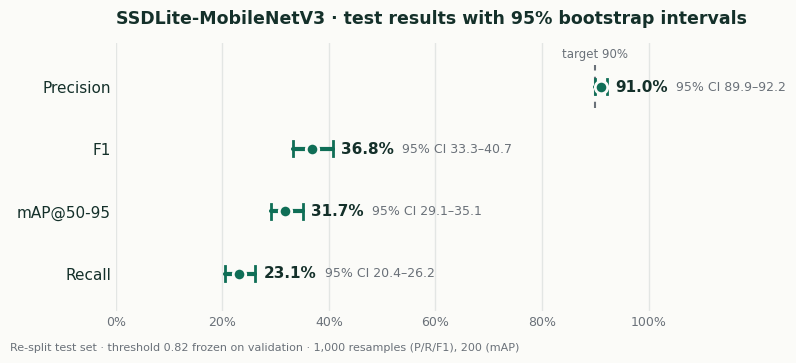

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

# SSDLite-MobileNetV3 — test set (re-split), threshold 0.82 frozen on validation
# values from the bootstrap output (1000 resamples P/R/F1, 200 resamples mAP)
rows = [  # (label, point, lo, hi)
    ("Precision",  91.0, 89.9, 92.2),
    ("F1",         36.8, 33.3, 40.7),
    ("mAP@50-95",  31.7, 29.1, 35.1),
    ("Recall",     23.1, 20.4, 26.2),
]
INK, MUTED, GRID, BG, ACCENT = "#14302A", "#6A7179", "#E3E6E4", "#FBFBF8", "#0F6E56"

fig, ax = plt.subplots(figsize=(8, 3.6), dpi=100)
fig.patch.set_facecolor(BG); ax.set_facecolor(BG)
ys = list(range(len(rows)))[::-1]
for y, (name, p, lo, hi) in zip(ys, rows):
    ax.plot([lo, hi], [y, y], color=ACCENT, lw=3, solid_capstyle="round", zorder=2)
    ax.plot([lo, lo], [y-0.12, y+0.12], color=ACCENT, lw=2, zorder=2)
    ax.plot([hi, hi], [y-0.12, y+0.12], color=ACCENT, lw=2, zorder=2)
    ax.scatter([p], [y], s=80, color=ACCENT, edgecolor=BG, linewidth=2, zorder=3)
    ax.text(hi + 1.5, y, f"{p:.1f}%", va="center", ha="left", fontsize=11, color=INK, weight="bold")
    ax.text(hi + 13, y, f"95% CI {lo:.1f}–{hi:.1f}", va="center", ha="left", fontsize=9, color=MUTED)

# precision target, drawn only on the precision row
py = ys[0]
ax.plot([90, 90], [py-0.35, py+0.35], color=MUTED, lw=1.5, ls=(0, (3, 3)), zorder=1)
ax.text(90, py+0.42, "target 90%", ha="center", va="bottom", fontsize=8.5, color=MUTED)

ax.set_yticks(ys); ax.set_yticklabels([r[0] for r in rows], fontsize=11, color=INK)
ax.set_xlim(0, 118); ax.set_xticks(range(0, 101, 20))
ax.set_xticklabels([f"{t}%" for t in range(0, 101, 20)], fontsize=9, color=MUTED)
ax.set_ylim(-0.6, len(rows)-0.3)
ax.grid(axis="x", color=GRID, lw=1); ax.set_axisbelow(True)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0)
ax.set_title("SSDLite-MobileNetV3 · test results with 95% bootstrap intervals",
             loc="left", fontsize=12.5, color=INK, weight="bold", pad=14)
fig.text(0.01, 0.01, "Re-split test set · threshold 0.82 frozen on validation · 1,000 resamples (P/R/F1), 200 (mAP)",
         fontsize=8, color=MUTED)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("ssdlite_ci_small.png", facecolor=BG)
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
<All keys matched successfully>


Saving photo_2026-10-14_09-55-32.jpg to photo_2026-10-14_09-55-32 (4).jpg


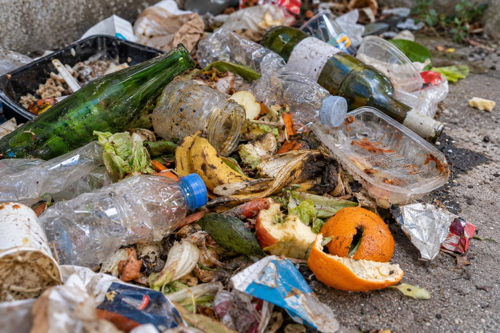

No waste detected. Organic share is unavailable.


In [ ]:
from google.colab import drive, files
drive.mount("/content/drive")

import torch
from torchvision.models.detection import ssdlite320_mobilenet_v3_large
from torchvision.transforms.functional import to_tensor
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display
from io import BytesIO
from pathlib import Path

# SSDLite — first version on the re-split
MODEL_PATH = Path("/content/drive/MyDrive/garbage_outputs/ssdlite_resplit/best.pt")
assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"

# threshold frozen on validation (precision >= 90%), re-split
CONFIDENCE = 0.82
MAX_DET = 100   # shared protocol

# dataset class order (data.yaml) — label 0 in SSDLite is background
CLASS_NAMES = ["BIODEGRADABLE", "CARDBOARD", "GLASS", "METAL", "PAPER", "PLASTIC"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ckpt = torch.load(MODEL_PATH, map_location="cpu", weights_only=False)
if isinstance(ckpt, torch.nn.Module):
    upload_model = ckpt
else:
    sd = ckpt.get("model", ckpt.get("model_state_dict", ckpt.get("state_dict", ckpt)))
    n = sd["head.classification_head.module_list.0.1.weight"].shape[0] // 6
    upload_model = ssdlite320_mobilenet_v3_large(weights=None, weights_backbone=None,
                                                 num_classes=n)
    print(upload_model.load_state_dict(sd, strict=True))

num_classes = upload_model.head.classification_head.num_columns
assert num_classes == len(CLASS_NAMES) + 1, \
    f"Expected 7 classes (background + 6), checkpoint has {num_classes}"

upload_model.detections_per_img = MAX_DET
upload_model.to(device).eval()

organic_ids = {
    i + 1  # +1 because 0 = background
    for i, name in enumerate(CLASS_NAMES)
    if name in {"BIODEGRADABLE", "ORGANIC", "ORGANIC_WASTE"}
}
assert organic_ids, "Organic class not found"

uploaded = files.upload()

for filename, image_bytes in uploaded.items():
    picture = ImageOps.exif_transpose(
        Image.open(BytesIO(image_bytes))
    ).convert("RGB")

    with torch.no_grad():
        out = upload_model([to_tensor(picture).to(device)])[0]

    keep = out["scores"] >= CONFIDENCE
    boxes = out["boxes"][keep].cpu().numpy()
    scores = out["scores"][keep].cpu().numpy()
    classes = out["labels"][keep].cpu().numpy().astype(int)

    annotated = picture.copy()
    draw = ImageDraw.Draw(annotated)
    for (x1, y1, x2, y2), s, c in zip(boxes, scores, classes):
        color = "red" if c in organic_ids else "lime"
        draw.rectangle([x1, y1, x2, y2], outline=color, width=3)
        draw.text((x1 + 3, y1 + 3), f"{CLASS_NAMES[c - 1]} {s:.2f}", fill=color)

    preview = annotated.copy()
    preview.thumbnail((500, 500))   # medium size; lower = smaller
    display(preview)

    total = len(classes)
    organic = sum(int(c) in organic_ids for c in classes)

    if total == 0:
        print("No waste detected. Organic share is unavailable.")
    else:
        percentage = organic / total * 100

        print(f"Total detected waste: {total}")
        print(f"Organic objects: {organic}")
        print(f"Organic share: {percentage:.1f}%")

        if organic / total > 0.30:
            print("⚠️ Organic waste exceeds 30% of detected waste.")
        else:
            print("Organic waste does not exceed 30% of detected waste.")

    save_dir = MODEL_PATH.parent.parent / "uploaded_predictions"
    save_dir.mkdir(parents=True, exist_ok=True)
    annotated.save(save_dir / f"{Path(filename).stem}_detected.jpg")